# Training SchNet on rMD17 (ethanol)

This notebook trains the `xnn` **SchNet** from scratch on the paper's own
benchmark task: predicting the **energies and forces** of a molecular-dynamics
trajectory of a small organic molecule, ethaol. The dataset is downloaded in
seconds through the `xnn` hub and the model reproduces the [SchNet
manuscript](https://arxiv.org/pdf/1706.08566)'s headline at small scale:

* Training on joint **energy + force training** with the paper's loss weighting
  ($\rho = 0.01$): forces are calculated via autograd through the
  `ForceStressOutput` wrapper the `Trainer` adds (Thus, the model is
  energy-conserving by construction).
* The trainer's **loggers**: every epoch's losses and MAE/RMSE, averaged over
  the whole training and validation sets, go to `metrics.csv` which is used to
  draw the learning curves.
* An **energy/force parity** plot vs DFT labels on held-out conformations is created.
* A **smooth 1-D potential-energy scan**, the property that continuous filters +
  shifted softplus can calculate over discretized approaches.

The model implemented here is based on the paper's architecture ($F = 64$, $T =
3$, Gaussian RBFs every 0.1 Å with $\gamma = 10$ Å$^{-2}$). The implementation
is verified against the manuscripts' equations block by block in
`notebooks/fidelity_checks/gnn/schnet/schnet_verification.ipynb`.

<div style="background: rgba(33, 150, 243, 0.10); border-left: 4px solid #2196f3; padding: 0.6em 1em; margin: 0.8em 0; border-radius: 0 4px 4px 0;"> 

<b>Note:</b> Run with this notebook with <b>xnn</b> kernel (which uses the GPU
when available). See the documentation or <b>pyproject.toml</b> for installation
instructions.
</div>

## 0. Setup and data

In [1]:
import time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import torch
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)

from xnn.common.data import load_dataset

In [2]:
# The paper trains without a distance cutoff -- its RBF grid just ends beyond
# every pair distance. Ethanol spans < 5 A, so a 10 A radius reproduces that
# no-cutoff setting (complete graph) with a matching 0.1 A RBF grid
CUTOFF, N_RBF = 10.0, 101

# Load the RMD17 ethanol dataset, which is small enough to fit in memory
splits = load_dataset("rmd17", molecule="ethanol", n_train=1000, n_test=500, quiet=True)

# Split the dataset into training and testing sets
train_structs, test_structs = splits["train"], splits["test"]

# Count the number of atoms in the first training structure
N_ATOMS = len(train_structs[0]["atomic_numbers"])

# Print the number of training and testing structures, as well as the number of
# atoms per molecule
print(
    f"train {len(train_structs)}  test {len(test_structs)}  "
    f"atoms/molecule {N_ATOMS}"
)

train 1000  test 500  atoms/molecule 9


## 1. Per-atom energy standardization

SchNet inherits the Deep Tensor Neural Netrowk (DTNN)'s output convention: the
network predicts a *standardized* per-atom energy $\hat E_i$, and the final
contribution is

$$E_i = E_\sigma \hat E_i + E_\mu$$

where $E_\mu$ and $E_\sigma$ denote the mean and standard deviation of the
**energy per atom** over the training set, respectively. With the
zero-initialized output head, the model's first prediction is exactly the
training-set mean which may provide a good starting point for the training.

In [3]:
# Compute the mean and standard deviation of the energy per atom in the training
# set
E_train = np.array([s["energy"] for s in train_structs])
E_SHIFT = float(E_train.mean() / N_ATOMS)     # E_mu   (eV / atom)
E_SCALE = float(E_train.std() / N_ATOMS)      # E_sigma (eV / atom)

# Print the mean and standard deviation of the energy per atom, as well as the
# total-energy spread of the trajectory
print(f"E_mu = {E_SHIFT:.4f} eV/atom   E_sigma = {E_SCALE:.5f} eV/atom")
print(f"(total-energy spread of the trajectory: {E_train.std():.3f} eV)")

E_mu = -467.7363 eV/atom   E_sigma = 0.01981 eV/atom
(total-energy spread of the trajectory: 0.178 eV)


## 2. Build SchNet and train on energies + forces

The [SchNet manuscript](https://arxiv.org/pdf/1706.08566)'s combined loss is

$$\ell = \rho\,\|E - \hat E\|^2 + \frac{1}{n}\sum_i \|F_i + \partial\hat
E/\partial R_i\|^2$$

with $\rho = 0.01$. The `xnn` trainer normalizes the energy term per atom so
`energy_weight=1, force_weight=1` gives an effective energy/force ratio of
$1/n^2 = 1/81 \approx 0.012$, the paper's $\rho$. The `trainer` section of the
config picks the `best.pt` and the plateau scheduler follows the validation loss
and the error metrics that are being computed. The loggers decide where the
metrics will be stored/printed: a `CSVLogger` keeps every epoch in
`runs/schnet_rmd17/metrics.csv`, and a `ConsoleLogger` subclass prints to the
standard output interface every 50th epoch.

In [4]:
from torch.utils.data import Subset
from xnn.common.data import AtomicDataset
from xnn.common.config import (
    Config,
    ModelConfig,
    DataConfig,
    OptimConfig,
    TrainerConfig,
)
from xnn.common.train import ConsoleLogger, CSVLogger, Trainer

In [5]:
# Training hyperparameters
EPOCHS, BS, LR = 300, 32, 1e-3

# Create the training and testing datasets using the AtomicDataset class, with
# the specified cutoff distance
train_ds = AtomicDataset(train_structs, CUTOFF)
test_ds = AtomicDataset(test_structs, CUTOFF)

# Create a validation set of 100 structures from the training set, and use the
# remaining structures for training
n_val = 100
val_idx = list(range(n_val))
tr_idx = list(range(n_val, len(train_ds)))

# Create a configuration object for the SchNet model, specifying the model
# architecture, data parameters, optimization settings, and output directory
cfg = Config(
    model=ModelConfig(
        name="schnet",
        cutoff=CUTOFF,
        n_features=64,
        n_interactions=3,
        n_rbf=N_RBF,
        # the paper's model (no envelope, two activated filter layers, ssp readout),
        # initialized as in this run
        extra={"gamma": 10.0, "cutoff_fn": None, "filter_output_activation": True,
               "interaction_input_bias": True, "readout_activation": "ssp",
               "weight_init": "torch", "zero_init_readout": True,
               "energy_shift": E_SHIFT, "energy_scale": E_SCALE},
    ),
    data=DataConfig(cutoff=CUTOFF, batch_size=BS),
    optim=OptimConfig(
        lr=LR, epochs=EPOCHS, energy_weight=1.0, force_weight=1.0, scheduler="plateau"
    ),
    trainer=TrainerConfig(monitor="val/loss", metrics=["mae", "rmse"]),
    output_dir="runs/schnet_rmd17",
)

In [6]:
class EveryNEpochs(ConsoleLogger):
    """Prints the epoch lines of every n-th epoch and the test result."""

    def __init__(self, n):
        super().__init__()
        self.n = n

    def log_metrics(self, metrics, step):
        if "epoch" not in metrics or (metrics["epoch"] + 1) % self.n == 0:
            super().log_metrics(metrics, step)


# Every epoch goes to runs/schnet_rmd17/metrics.csv, every 50th to the screen
csv_logger = CSVLogger()
trainer = Trainer(
    cfg,
    Subset(train_ds, tr_idx),
    Subset(train_ds, val_idx),
    test_ds,
    logger=[csv_logger, EveryNEpochs(50)],
)

# Count the number of parameters in the SchNet model and print it along with the
# device being used for training
n_params = sum(p.numel() for p in trainer.module.parameters())
print(f"SchNet parameters: {n_params:,}  |  device: {trainer.device}")

# Train the SchNet model for the specified number of epochs and print the total
# training time
t0 = time.time()
metrics = trainer.fit()
print(f"trained {EPOCHS} epochs in {time.time()-t0:.0f}s")

SchNet parameters: 78,117  |  device: cuda
epoch   49 | train loss 2.4335e-02 (energy 2.068e-04, force 2.413e-02) | val loss 3.5942e-02 (energy 1.151e-04, force 3.583e-02)
          val mae: energy 9.378e-03, forces 1.339e-01 | rmse: energy 1.073e-02, forces 1.893e-01
epoch   99 | train loss 1.3431e-02 (energy 1.310e-04, force 1.330e-02) | val loss 1.6855e-02 (energy 1.426e-04, force 1.671e-02)
          val mae: energy 1.090e-02, forces 9.006e-02 | rmse: energy 1.194e-02, forces 1.293e-01
epoch  149 | train loss 9.3349e-03 (energy 6.929e-05, force 9.266e-03) | val loss 1.1998e-02 (energy 1.633e-05, force 1.198e-02)
          val mae: energy 3.217e-03, forces 7.771e-02 | rmse: energy 4.041e-03, forces 1.095e-01
epoch  199 | train loss 5.4274e-03 (energy 2.104e-05, force 5.406e-03) | val loss 7.8981e-03 (energy 3.643e-05, force 7.862e-03)
          val mae: energy 5.387e-03, forces 6.109e-02 | rmse: energy 6.036e-03, forces 8.867e-02
epoch  249 | train loss 5.0365e-03 (energy 9.388e-06,

## 3. Learning curves

The loss and the validation MAEs of every epoch, read back from `metrics.csv`
(the energy MAE is per atom), can be plotted as shown below

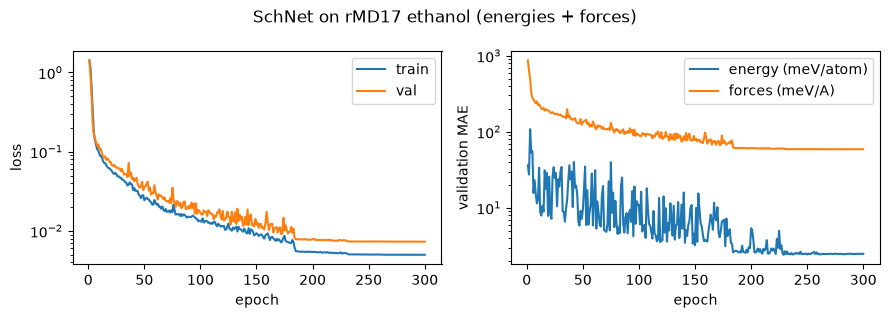

In [7]:
import csv

# One row per epoch, then one row with the test metrics
with open(csv_logger.path) as f:
    rows = [r for r in csv.DictReader(f) if r["epoch"]]

# Extract the data for plotting
col = lambda key: np.array([float(r[key]) for r in rows])
epoch = col("epoch") + 1

# Plot the training and validation loss
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2))
a1.plot(epoch, col("train/loss"), label="train")
a1.plot(epoch, col("val/loss"), label="val")
a1.set_yscale("log")
a1.set_xlabel("epoch")
a1.set_ylabel("loss")
a1.legend()
a2.plot(epoch, col("val/energy_mae") * 1e3, label="energy (meV/atom)")
a2.plot(epoch, col("val/forces_mae") * 1e3, label="forces (meV/A)")
a2.set_yscale("log")
a2.set_xlabel("epoch")
a2.set_ylabel("validation MAE")
a2.legend()
fig.suptitle("SchNet on rMD17 ethanol (energies + forces)")
fig.tight_layout()
fig.savefig("schnet_loss_curves.png", dpi=110)
plt.show()

## 4. Energy & force parity vs DFT

We load `best.pt`, the weights of the epoch with the lowest validation loss (the
checkpoint `schnet_ethanol_md.ipynb` runs), predict on the 500 held-out
conformations and compare to the reference DFT values. The MAEs are in kcal/mol
with the energy error per molecule in order to be consist with the [SchNet
manuscript](https://arxiv.org/pdf/1706.08566). 

For comparison: SchNet, trained on $N = 1000$ MD17 ethanol conformations,
reaches MAE of 0.08 kcal/mol (energy) and 0.39 kcal/mol/Å (forces) in Table 2 of
the [SchNet manuscript](https://arxiv.org/pdf/1706.08566), with $\approx$ 10x
longer training and learning-rate decay. This 300-epoch run lands within a few
times those numbers (sub-kcal/mol energies).

In [8]:
from torch.utils.data import DataLoader
from xnn.common.data import collate
from xnn.common.models.hub import from_pretrained

# Set the device to the one used by the trainer
device = str(trainer.device)

# Load the best model checkpoint from the training run and set it to evaluation
# mode
model = from_pretrained("runs/schnet_rmd17/best.pt", device=device).eval()

# Define the conversion factor from electron volts to kilocalories per mole
EV2KCAL = 23.060541945329334

# Evaluate the model on the test dataset and compute the predicted and reference
# energies and forces
E_pred, E_ref, F_pred, F_ref = [], [], [], []
for batch in DataLoader(test_ds, batch_size=50, collate_fn=collate):
    batch = batch.to(device)
    out = model(batch)
    E_pred.append(out["energy"].detach().cpu().numpy())
    E_ref.append(batch.energy.detach().cpu().numpy())
    F_pred.append(out["forces"].detach().cpu().numpy())
    F_ref.append(batch.forces.detach().cpu().numpy())
E_pred, E_ref = np.concatenate(E_pred), np.concatenate(E_ref)
F_pred, F_ref = np.concatenate(F_pred), np.concatenate(F_ref)

# Compute the mean absolute error (MAE) and root mean square error (RMSE) for
# both energies and forces, and print the results in both meV and kcal/mol units
e_mae = np.abs(E_pred - E_ref).mean()
f_mae = np.abs(F_pred - F_ref).mean()
e_rmse = np.sqrt(np.mean((E_pred - E_ref) ** 2))
f_rmse = np.sqrt(np.mean((F_pred - F_ref) ** 2))
print(f"energy MAE : {e_mae*1e3:6.2f} meV    ({e_mae*EV2KCAL:.3f} kcal/mol)")
print(f"force  MAE : {f_mae*1e3:6.2f} meV/A  ({f_mae*EV2KCAL:.3f} kcal/mol/A)")
print(f"energy RMSE: {e_rmse*1e3:6.2f} meV    ({e_rmse*EV2KCAL:.3f} kcal/mol)")
print(f"force  RMSE: {f_rmse*1e3:6.2f} meV/A  ({f_rmse*EV2KCAL:.3f} kcal/mol/A)")

energy MAE :  23.62 meV    (0.545 kcal/mol)
force  MAE :  59.15 meV/A  (1.364 kcal/mol/A)
energy RMSE:  30.68 meV    (0.707 kcal/mol)
force  RMSE:  83.28 meV/A  (1.921 kcal/mol/A)


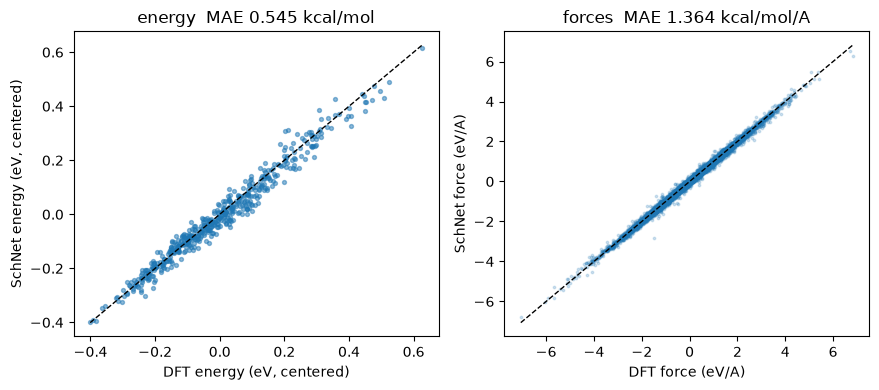

In [ ]:
# Plot the parity between the predicted and reference energies and forces, with
# the mean absolute error (MAE) displayed in the titles 
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 4))
a1.scatter(E_ref - E_ref.mean(), E_pred - E_ref.mean(), s=8, alpha=0.5)
lim = np.array([(E_ref - E_ref.mean()).min(), (E_ref - E_ref.mean()).max()])
a1.plot(lim, lim, "k--", lw=1)
a1.set_xlabel("DFT energy (eV, centered)")
a1.set_ylabel("SchNet energy (eV, centered)")
a1.set_title(f"energy  MAE {e_mae*EV2KCAL:.3f} kcal/mol")
a2.scatter(F_ref.ravel(), F_pred.ravel(), s=3, alpha=0.2)
lim = np.array([F_ref.min(), F_ref.max()])
a2.plot(lim, lim, "k--", lw=1)
a2.set_xlabel("DFT force (eV/A)")
a2.set_ylabel("SchNet force (eV/A)")
a2.set_title(f"forces  MAE {f_mae*EV2KCAL:.3f} kcal/mol/A")
fig.tight_layout()
fig.savefig("schnet_parity.png", dpi=110)
plt.show()

## 5. A smooth 1-D potential-energy scan

One of the reasons behind creating a *continuous* filter in SchNet is having a
smooth, differentiable potential energy surface (the paper's Fig. 1 contrasts
this with the jagged surface a discretized filter produces). We stretch the C-O
bond of a test geometry and evaluate the trained SchNet along the scan through
its ASE calculator: a smooth single-well curve is what enables stable geometry
optimization and MD.

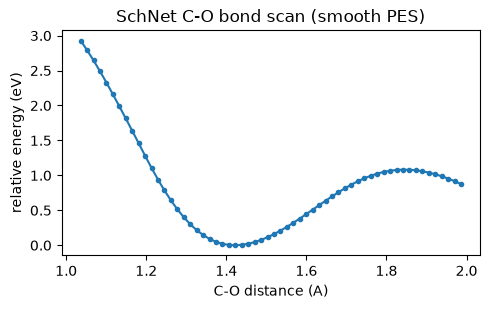

In [10]:
from ase import Atoms
from xnn.common.deploy import XNNCalculator

# Create an ASE calculator using the trained SchNet model, with the specified
# cutoff distance and device
calc = XNNCalculator(model, cutoff=CUTOFF, device=device)

# Extract the atomic numbers and positions of the first test structure, and
# create an ASE Atoms object with the SchNet calculator
s = test_structs[0]
atoms = Atoms(numbers=s["atomic_numbers"], positions=s["pos"], calculator=calc)
Z, pos0 = atoms.numbers, atoms.positions.copy()

# Ethanol: stretch the C-O bond (the O and the nearest C)
O = int(np.flatnonzero(Z == 8)[0])
Cs = np.flatnonzero(Z == 6)
C = int(Cs[np.linalg.norm(pos0[Cs] - pos0[O], axis=1).argmin()])
axis = pos0[O] - pos0[C]
r0 = float(np.linalg.norm(axis))
axis /= r0

# Perform a bond scan by varying the C-O distance and computing the potential
# energy at each distance using the SchNet calculator. The energies are then
# shifted so that the minimum energy is zero
scan = np.linspace(-0.35, 0.6, 60)
energies = []
for dr in scan:
    pos = pos0.copy(); pos[O] += dr * axis
    atoms.positions = pos
    energies.append(atoms.get_potential_energy())
energies = np.array(energies) - min(energies)

# Plot the potential energy surface (PES) of the C-O bond scan, with the C-O
# distance on the x-axis and the relative energy on the y-axis
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(r0 + scan, energies, "o-", ms=3)
ax.set_xlabel("C-O distance (A)"); ax.set_ylabel("relative energy (eV)")
ax.set_title("SchNet C-O bond scan (smooth PES)")
fig.tight_layout()
fig.savefig("schnet_bond_scan.png", dpi=110)
plt.show()

## Summary

- The `xnn` SchNet reproduces the [SchNet
  manuscript](https://arxiv.org/pdf/1706.08566)'s results on the rMD17 ethanol
  dataset, achieving sub-kcal/mol accuracy in energy and force predictions.
- The model's continuous filter architecture allows for smooth potential energy
  surfaces, which is crucial for stable geometry optimization and molecular
  dynamics simulations.
- The training process, including energy and force loss weighting, learning rate
  scheduling, and logging, is effectively managed by the `xnn` Trainer,
  demonstrating the framework's capability for handling complex machine learning
  tasks in computational chemistry.

## References

- [Schütt et al., *SchNet: A continuous-filter convolutional neural network for modeling quantum interactions* arXiv.1706.08566 (2017)](https://arxiv.org/pdf/1706.08566)
- [Schütt et al., *SchNet: A deep learning architecture for molecules and materials*, J. Chem. Phys. 148, 241722 (2018)](https://doi.org/10.1063/1.5019779)